In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Model saving
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving loan_train.csv to loan_train.csv


In [3]:
# Load loan dataset
loan_df = pd.read_csv("loan_train.csv")

# Display first 10 records
print("First 10 rows:")
display(loan_df.head(10))

# Dataset shape
print("\nDataset Shape:", loan_df.shape)

# Dataset information
print("\nDataset Information:")
loan_df.info()

# Statistical summary
print("\nStatistical Summary:")
display(loan_df.describe())

# Check missing values
print("\nMissing Values:")
print(loan_df.isnull().sum())

First 10 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N



Dataset Shape: (614, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Statistical Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [4]:
print("Duplicate rows:", loan_df.duplicated().sum())

# Remove duplicate rows if present
loan_df = loan_df.drop_duplicates()

print("Dataset shape after duplicate removal:", loan_df.shape)

Duplicate rows: 0
Dataset shape after duplicate removal: (614, 13)


Loan Status Distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


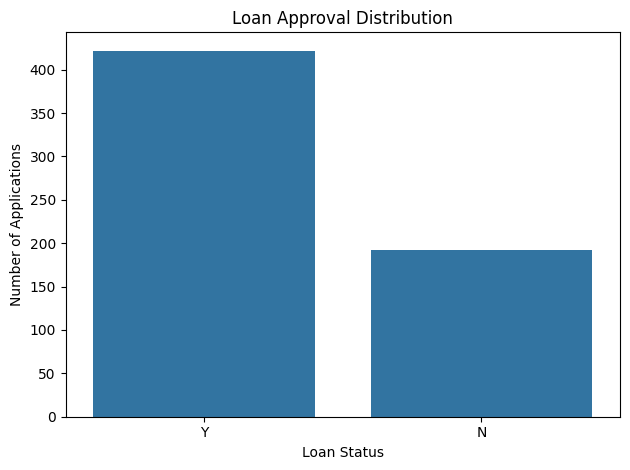

In [5]:
print("Loan Status Distribution:")
print(loan_df["Loan_Status"].value_counts())

sns.countplot(
    data=loan_df,
    x="Loan_Status"
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.tight_layout()
plt.savefig("loan_status_distribution.png", dpi=300)
plt.show()

In [6]:
# Input features
X = loan_df.drop(columns=["Loan_Status"])

# Target variable
y = loan_df["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

print("Input Features:")
display(X.head())

print("\nTarget Values:")
print(y.head())

print("\nTarget Distribution:")
print(y.value_counts())

Input Features:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban



Target Values:
0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64

Target Distribution:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

Training records: 491
Testing records: 123

Training dataset shape: (491, 12)
Testing dataset shape: (123, 12)


In [8]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical Features:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [9]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# Create Random Forest pipeline
loan_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train model
loan_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [11]:
# Predict loan approval
y_pred = loan_model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred
})

display(results.head(15))

,Actual Status,Predicted Status
0,0,0
1,1,1
2,1,1
3,1,1
4,1,1
5,0,1
6,1,1
7,1,1
8,1,1
9,1,1


In [12]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("RANDOM FOREST MODEL PERFORMANCE")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")

RANDOM FOREST MODEL PERFORMANCE
Accuracy: 85.37 %
Precision: 83.84 %
Recall: 97.65 %


In [13]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Rejected", "Approved"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.92      0.58      0.71        38
    Approved       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



Confusion Matrix:
[[22 16]
 [ 2 83]]


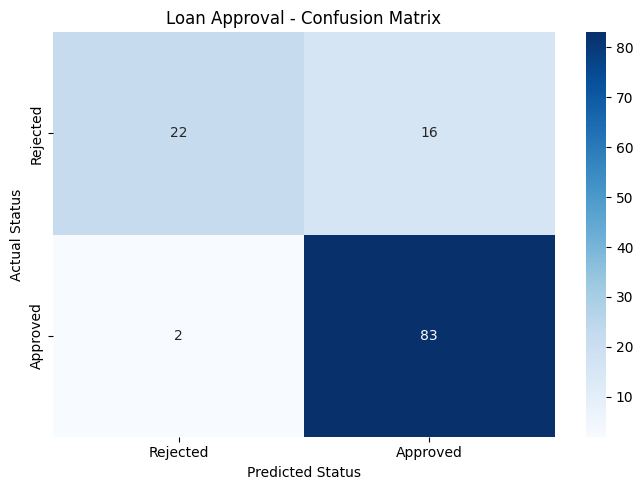

In [14]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Loan Approval - Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")

plt.tight_layout()

plt.savefig("loan_confusion_matrix.png", dpi=300)

plt.show()

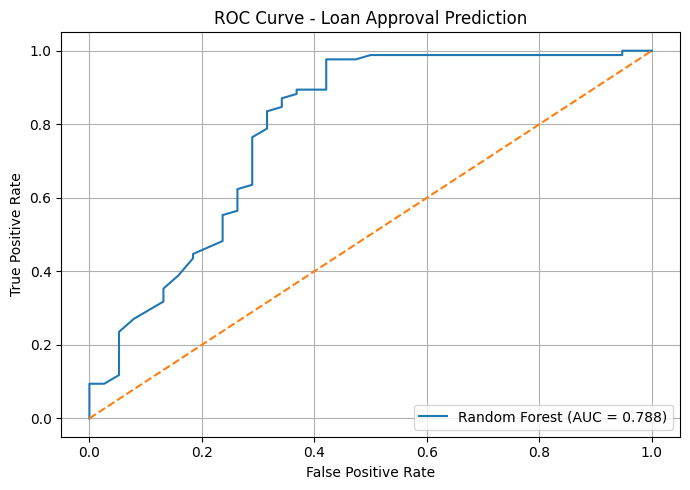

ROC AUC Score: 0.7884


In [15]:
# Get approval probabilities
y_probability = loan_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

# Calculate AUC
auc_score = roc_auc_score(
    y_test,
    y_probability
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve - Loan Approval Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("loan_roc_curve.png", dpi=300)

plt.show()

print("ROC AUC Score:", round(auc_score, 4))

In [20]:
# STEP 1: Prepare corrected features and target

X = loan_df.drop(
    columns=["Loan_ID", "Loan_Status"],
    errors="ignore"
)

y = loan_df["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

# STEP 2: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# STEP 3: Identify feature types

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# STEP 4: Create preprocessing pipelines

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# STEP 5: Create a fresh Random Forest model

loan_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# STEP 6: Train the corrected model

loan_model.fit(X_train, y_train)

print("Corrected Random Forest model trained successfully!")
print("Loan_ID present in features:", "Loan_ID" in X.columns)

Corrected Random Forest model trained successfully!
Loan_ID present in features: False


In [16]:
# Create a new applicant
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "1",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 2000,
    "LoanAmount": 150,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}])

print("New Applicant Details:")
display(new_applicant)

New Applicant Details:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,Male,Yes,1,Graduate,No,5000,2000,150,360,1.0,Urban


In [18]:
# Remove Loan_ID from input features
X = loan_df.drop(
    columns=["Loan_ID", "Loan_Status"],
    errors="ignore"
)

# Separate target variable
y = loan_df["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

print("Input Features:")
print(X.columns.tolist())

print("\nLoan_ID present:", "Loan_ID" in X.columns)

Input Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Loan_ID present: False


In [21]:
# Create a new applicant
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "1",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 2000,
    "LoanAmount": 150,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}])

# Verify feature columns
print("Applicant columns match:",
      list(new_applicant.columns) == list(X.columns))

# Predict loan approval
new_prediction = loan_model.predict(new_applicant)

# Calculate approval probability
new_probability = loan_model.predict_proba(new_applicant)[0][1]

if new_prediction[0] == 1:
    print("Model Prediction: Loan Approved")
else:
    print("Model Prediction: Loan Rejected")

print(
    "Predicted Approval Probability:",
    round(new_probability * 100, 2),
    "%"
)

Applicant columns match: True
Model Prediction: Loan Approved
Predicted Approval Probability: 78.0 %


In [22]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    loan_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:")
print(cv_scores)

print("\nIndividual Fold Accuracy:")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print(
    "\nAverage Cross Validation Accuracy:",
    round(cv_scores.mean() * 100, 2),
    "%"
)

print(
    "Standard Deviation:",
    round(cv_scores.std(), 4)
)

Cross Validation Scores:
[0.74747475 0.80612245 0.78571429 0.73469388 0.75510204]

Individual Fold Accuracy:
Fold 1: 74.75%
Fold 2: 80.61%
Fold 3: 78.57%
Fold 4: 73.47%
Fold 5: 75.51%

Average Cross Validation Accuracy: 76.58 %
Standard Deviation: 0.0262


In [23]:
# Create SVM pipeline
svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

print("SVM Pipeline Created Successfully!")

SVM Pipeline Created Successfully!


In [24]:
# Define parameter combinations
param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}

print("Parameter Grid:")
print(param_grid)

Parameter Grid:
{'classifier__C': [0.1, 1, 10], 'classifier__kernel': ['linear', 'rbf'], 'classifier__gamma': ['scale', 'auto']}


In [25]:
# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Train and search for best parameters
grid_search.fit(X_train, y_train)

print("\nGrid Search Completed!")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Grid Search Completed!

Best Parameters:
{'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}

Best Cross Validation Accuracy:
79.84 %


In [26]:
# Get best model
best_svm_model = grid_search.best_estimator_

# Predict test data
svm_predictions = best_svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

print(
    "Best SVM Test Accuracy:",
    round(svm_accuracy * 100, 2),
    "%"
)

Best SVM Test Accuracy: 85.37 %


,Model,Accuracy (%)
0,Random Forest,85.365854
1,Optimized SVM,85.365854


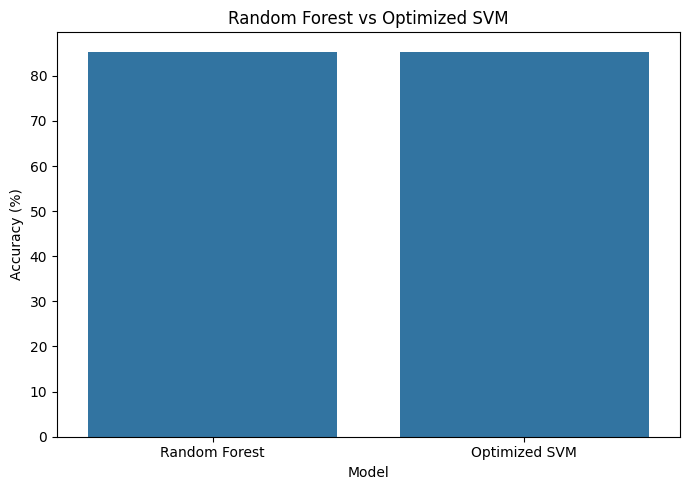

In [27]:
model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Optimized SVM"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        svm_accuracy * 100
    ]
})

display(model_results)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Random Forest vs Optimized SVM")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")

plt.tight_layout()

plt.savefig("loan_model_comparison.png", dpi=300)

plt.show()

In [28]:
# Save the trained Random Forest pipeline
joblib.dump(
    loan_model,
    "loan_approval_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [29]:
from google.colab import files

files.download("loan_approval_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Load trained model
loaded_model = joblib.load(
    "loan_approval_model.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [31]:
# Select one unseen test applicant
test_applicant = X_test.iloc[[0]].copy()

print("Applicant Details:")
display(test_applicant)

# Make prediction
loaded_prediction = loaded_model.predict(
    test_applicant
)

# Get approval probability
loaded_probability = loaded_model.predict_proba(
    test_applicant
)[0][1]

# Display result
if loaded_prediction[0] == 1:
    print("Prediction: Loan Approved")
else:
    print("Prediction: Loan Rejected")

print(
    "Approval Probability:",
    round(loaded_probability * 100, 2),
    "%"
)

Applicant Details:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


Prediction: Loan Rejected
Approval Probability: 4.5 %


In [32]:
# Compare original and loaded model predictions
original_prediction = loan_model.predict(test_applicant)

loaded_prediction = loaded_model.predict(test_applicant)

print(
    "Predictions Match:",
    np.array_equal(
        original_prediction,
        loaded_prediction
    )
)

Predictions Match: True
